IMPORT LIBRARIES

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LOAD DATASET

In [47]:
# Load the data
col_mat_nuw_df = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/col_mat_nuw_output.csv", names=["HCHO reading", "Location", "Current Date", "Next Date"])
mon_kur_jaf_df = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/mon_kur_jaf_output.csv", names=["HCHO reading", "Location", "Current Date", "Next Date"])
kan_df = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/kan_output.csv", names=["HCHO reading", "Location", "Current Date", "Next Date"])

# Concatenate all datasets
data = pd.concat([col_mat_nuw_df, mon_kur_jaf_df, kan_df])

# Check for missing values in "HCHO reading" column
print("Number of missing values:", data["HCHO reading"].isnull().sum())
print(data.head())

Number of missing values: 4864
   HCHO reading        Location Current Date   Next Date
0      0.000197  Colombo Proper   2019-01-01  2019-01-02
1      0.000263  Colombo Proper   2019-01-02  2019-01-03
2      0.000099  Colombo Proper   2019-01-03  2019-01-04
3      0.000210  Colombo Proper   2019-01-04  2019-01-05
4      0.000179  Colombo Proper   2019-01-05  2019-01-06


DATA PREPROCESSING

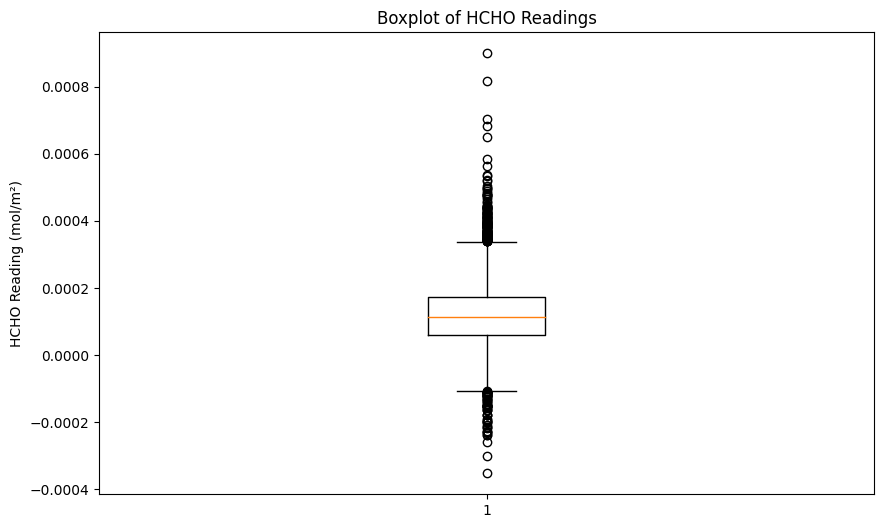

In [48]:
# Remove rows with missing values
data_cleaned = data.dropna(subset=["HCHO reading"])

# Plot boxplot after removing missing values
plt.figure(figsize=(10, 6))
plt.boxplot(data_cleaned["HCHO reading"])
plt.title("Boxplot of HCHO Readings")
plt.ylabel("HCHO Reading (mol/m²)")
plt.show()

In [49]:
# Remove outliers using IQR method
Q1 = data_cleaned["HCHO reading"].quantile(0.25)
Q3 = data_cleaned["HCHO reading"].quantile(0.75)
IQR = Q3 - Q1

# Define upper and lower bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter data based on bounds
data_cleaned = data_cleaned[(data_cleaned["HCHO reading"] >= lower_bound) & (data_cleaned["HCHO reading"] <= upper_bound)]

# Check the shape of the cleaned data
print("Shape of original data:", data.shape)
print("Shape of cleaned data:", data_cleaned.shape)


Shape of original data: (12782, 4)
Shape of cleaned data: (7703, 4)


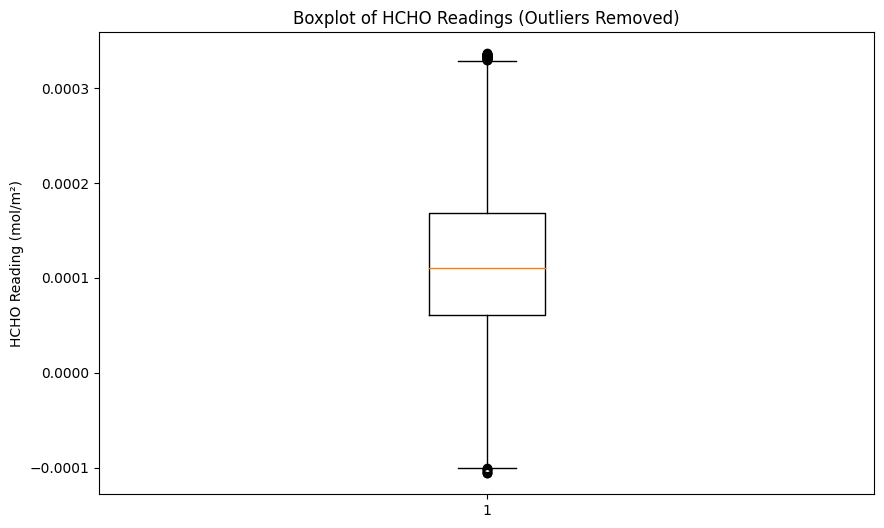

In [50]:
# Plot boxplot after removing outliers
plt.figure(figsize=(10, 6))
plt.boxplot(data_cleaned["HCHO reading"])
plt.title("Boxplot of HCHO Readings (Outliers Removed)")
plt.ylabel("HCHO Reading (mol/m²)")
plt.show()

In [51]:
# Convert date columns to datetime format
data_cleaned["Current Date"] = pd.to_datetime(data_cleaned["Current Date"])
data_cleaned["Next Date"] = pd.to_datetime(data_cleaned["Next Date"])

# Remove duplicate rows
data_cleaned = data_cleaned.drop_duplicates()

# Standardize location names (e.g., convert to lowercase)
data_cleaned["Location"] = data_cleaned["Location"].str.lower()

In [52]:
print(data_cleaned.head())

   HCHO reading        Location Current Date  Next Date
0      0.000197  colombo proper   2019-01-01 2019-01-02
1      0.000263  colombo proper   2019-01-02 2019-01-03
2      0.000099  colombo proper   2019-01-03 2019-01-04
3      0.000210  colombo proper   2019-01-04 2019-01-05
4      0.000179  colombo proper   2019-01-05 2019-01-06


                      count      mean       std       min       25%       50%  \
Location                                                                        
bibile, monaragala   1098.0  0.000125  0.000081 -0.000103  0.000071  0.000124   
colombo proper       1273.0  0.000149  0.000084 -0.000099  0.000090  0.000146   
deniyaya, matara      953.0  0.000088  0.000076 -0.000099  0.000038  0.000081   
jaffna proper        1433.0  0.000106  0.000066 -0.000106  0.000063  0.000101   
kandy proper         1014.0  0.000107  0.000082 -0.000105  0.000053  0.000106   
kurunegala proper    1200.0  0.000131  0.000076 -0.000100  0.000078  0.000125   
nuwara eliya proper   732.0  0.000088  0.000079 -0.000098  0.000035  0.000082   

                          75%       max  
Location                                 
bibile, monaragala   0.000183  0.000336  
colombo proper       0.000210  0.000337  
deniyaya, matara     0.000137  0.000334  
jaffna proper        0.000145  0.000334  
kandy proper      

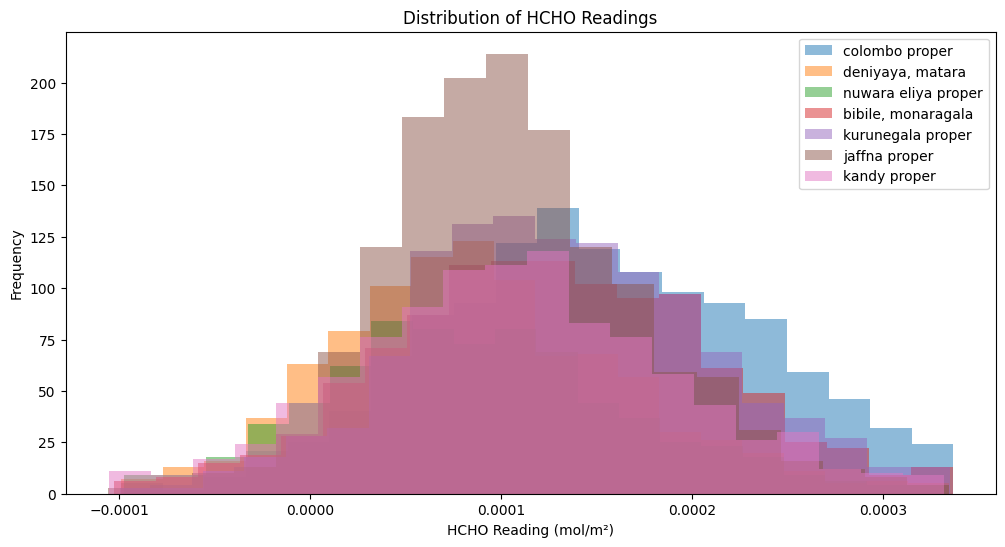

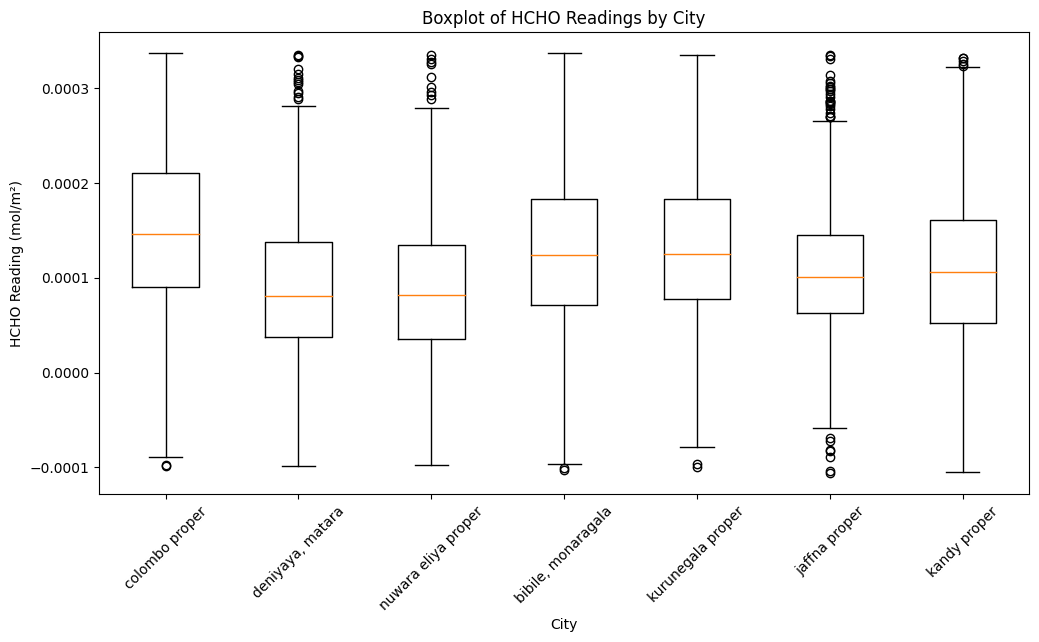

In [53]:
# Descriptive statistics
summary_stats = data_cleaned.groupby("Location")["HCHO reading"].describe()
print(summary_stats)

# Visualization - Histograms
plt.figure(figsize=(12, 6))
for city in data_cleaned["Location"].unique():
    plt.hist(data_cleaned[data_cleaned["Location"] == city]["HCHO reading"], bins=20, alpha=0.5, label=city)
plt.title("Distribution of HCHO Readings")
plt.xlabel("HCHO Reading (mol/m²)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# Visualization - Boxplot
plt.figure(figsize=(12, 6))
plt.boxplot([data_cleaned[data_cleaned["Location"] == city]["HCHO reading"] for city in data_cleaned["Location"].unique()],
            labels=data_cleaned["Location"].unique())
plt.title("Boxplot of HCHO Readings by City")
plt.xlabel("City")
plt.ylabel("HCHO Reading (mol/m²)")
plt.xticks(rotation=45)
plt.show()

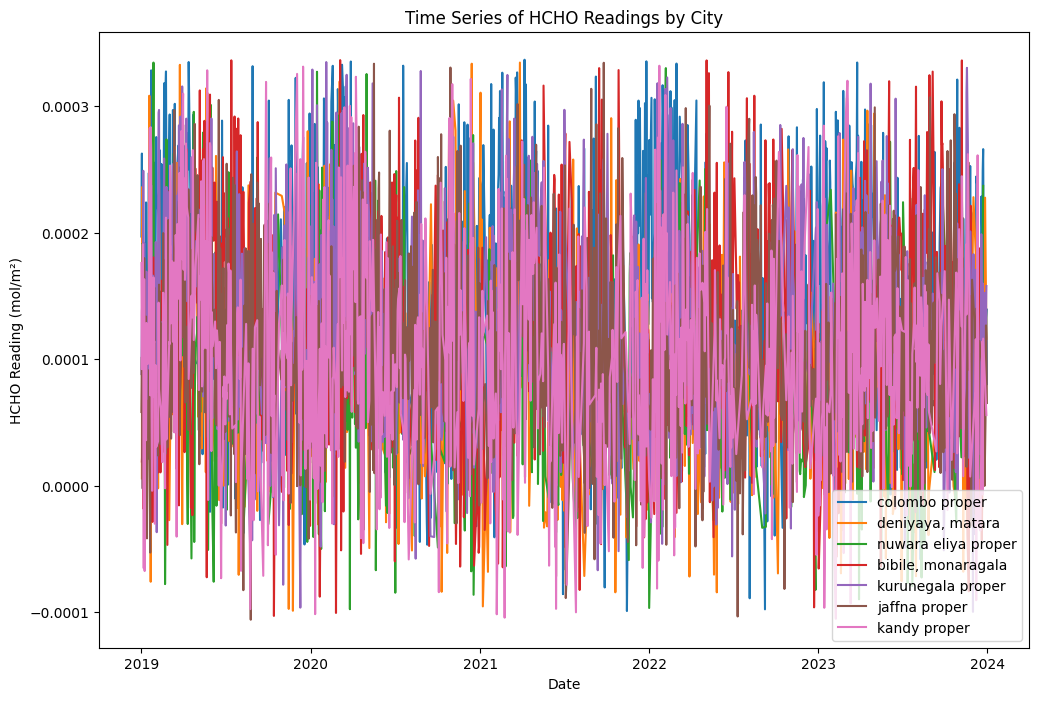

In [54]:
import seaborn as sns

# Convert 'Current Date' to datetime format
data_cleaned['Current Date'] = pd.to_datetime(data_cleaned['Current Date'])

# Plot time series graphs for each city
plt.figure(figsize=(12, 8))
for city in data_cleaned['Location'].unique():
    sns.lineplot(data=data_cleaned[data_cleaned['Location'] == city], x='Current Date', y='HCHO reading', label=city)
plt.title('Time Series of HCHO Readings by City')
plt.xlabel('Date')
plt.ylabel('HCHO Reading (mol/m²)')
plt.legend()
plt.show()


WEATHER DATA FOR COLOMBO, KURUNEGALA, NUWARA ELIYA

In [55]:
# Load weather data for Colombo
colombo_weather = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/ColomboDailyPrecipTempDataCSV.csv", header=0, names=["Station", "Location", "Date", "PRCP", "TEMPAVG", "TEMPMAX", "TEMPMIN"])

# Load weather data for Kurunegala
kurunegala_weather = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/KurunegalaDailyPrecipTempDataCSV.csv", header=0, names=["Station", "Location", "Date", "PRCP", "TEMPAVG", "TEMPMAX", "TEMPMIN"])

# Load weather data for Nuwara Eliya
nuwara_eliya_weather = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/NuwaraEliyaDailyPrecipTempCSV.csv", header=0, names=["Station", "Location", "Date", "PRCP", "TEMPAVG", "TEMPMAX", "TEMPMIN"])

print(colombo_weather.head())
print("Shape of original data:", colombo_weather.shape)

       Station     Location      Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN
0  CEM00043466  COLOMBO, CE  1/1/2019   0.0     27.5     31.7     23.4
1  CEM00043466  COLOMBO, CE  1/2/2019   0.0     25.8      NaN     23.1
2  CEM00043466  COLOMBO, CE  1/3/2019   0.0     27.1     32.1     23.1
3  CEM00043466  COLOMBO, CE  1/4/2019   0.0     27.1     32.6     22.5
4  CEM00043466  COLOMBO, CE  1/5/2019   0.0     27.2     32.3     23.5
Shape of original data: (1765, 7)


In [56]:
# Handle missing values
colombo_weather.dropna(inplace=True)
kurunegala_weather.dropna(inplace=True)
nuwara_eliya_weather.dropna(inplace=True)

# Convert date columns to datetime format
colombo_weather['Date'] = pd.to_datetime(colombo_weather['Date'])
kurunegala_weather['Date'] = pd.to_datetime(kurunegala_weather['Date'])
nuwara_eliya_weather['Date'] = pd.to_datetime(nuwara_eliya_weather['Date'])

# Check for duplicates
print("Duplicates in Colombo weather data:", colombo_weather.duplicated().sum())
print("Duplicates in Kurunegala weather data:", kurunegala_weather.duplicated().sum())
print("Duplicates in Nuwara Eliya weather data:", nuwara_eliya_weather.duplicated().sum())

# Remove duplicates
colombo_weather.drop_duplicates(inplace=True)
kurunegala_weather.drop_duplicates(inplace=True)
nuwara_eliya_weather.drop_duplicates(inplace=True)

colombo_weather["Location"] = colombo_weather["Location"].str.lower()
kurunegala_weather["Location"] = kurunegala_weather["Location"].str.lower()
nuwara_eliya_weather["Location"] = nuwara_eliya_weather["Location"].str.lower()

print(colombo_weather.head())
print(kurunegala_weather.head())
print(nuwara_eliya_weather.head())

Duplicates in Colombo weather data: 0
Duplicates in Kurunegala weather data: 0
Duplicates in Nuwara Eliya weather data: 0
       Station     Location       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN
0  CEM00043466  colombo, ce 2019-01-01   0.0     27.5     31.7     23.4
2  CEM00043466  colombo, ce 2019-01-03   0.0     27.1     32.1     23.1
3  CEM00043466  colombo, ce 2019-01-04   0.0     27.1     32.6     22.5
4  CEM00043466  colombo, ce 2019-01-05   0.0     27.2     32.3     23.5
5  CEM00043466  colombo, ce 2019-01-06   0.0     27.4     30.9     22.8
       Station        Location       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN
1  CEM00043441  kurunegala, ce 2019-01-03   0.0     27.4     30.5     21.9
2  CEM00043441  kurunegala, ce 2019-01-04   0.0     28.4     31.1     20.8
3  CEM00043441  kurunegala, ce 2019-01-05   0.0     28.7     32.1     18.5
4  CEM00043441  kurunegala, ce 2019-01-06   0.0     28.0     31.0     21.5
5  CEM00043441  kurunegala, ce 2019-01-07   0.0     26.9     31.5     2

In [57]:
print("Shape of cleaned data:", colombo_weather.shape)

Shape of cleaned data: (1277, 7)


In [58]:
print(data_cleaned.head())

   HCHO reading        Location Current Date  Next Date
0      0.000197  colombo proper   2019-01-01 2019-01-02
1      0.000263  colombo proper   2019-01-02 2019-01-03
2      0.000099  colombo proper   2019-01-03 2019-01-04
3      0.000210  colombo proper   2019-01-04 2019-01-05
4      0.000179  colombo proper   2019-01-05 2019-01-06


In [59]:
location_mapping = {
    "colombo proper": "colombo, ce",
    "kurunegala proper": "kurunegala, ce",
    "nuwara eliya proper": "nuwara eliya, ce"
}

data_cleaned['Location'] = data_cleaned['Location'].map(location_mapping)

In [60]:
# Merge weather data with HCHO dataset
merged_colombo = pd.merge(data_cleaned[data_cleaned["Location"] == "colombo, ce"], colombo_weather, left_on="Current Date", right_on="Date", how="left")
merged_kurunegala = pd.merge(data_cleaned[data_cleaned["Location"] == "kurunegala, ce"], kurunegala_weather, left_on="Current Date", right_on="Date", how="left")
merged_nuwara_eliya = pd.merge(data_cleaned[data_cleaned["Location"] == "kurunegala, ce"], nuwara_eliya_weather, left_on="Current Date", right_on="Date", how="left")

In [61]:
print("COLOMBO")
print(merged_colombo.head())
print("\nKURUNEGALA")
print(merged_kurunegala.head())
print("\nNUWARA")
print(merged_nuwara_eliya.head())

COLOMBO
   HCHO reading   Location_x Current Date  Next Date      Station  \
0      0.000197  colombo, ce   2019-01-01 2019-01-02  CEM00043466   
1      0.000263  colombo, ce   2019-01-02 2019-01-03          NaN   
2      0.000099  colombo, ce   2019-01-03 2019-01-04  CEM00043466   
3      0.000210  colombo, ce   2019-01-04 2019-01-05  CEM00043466   
4      0.000179  colombo, ce   2019-01-05 2019-01-06  CEM00043466   

    Location_y       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN  
0  colombo, ce 2019-01-01   0.0     27.5     31.7     23.4  
1          NaN        NaT   NaN      NaN      NaN      NaN  
2  colombo, ce 2019-01-03   0.0     27.1     32.1     23.1  
3  colombo, ce 2019-01-04   0.0     27.1     32.6     22.5  
4  colombo, ce 2019-01-05   0.0     27.2     32.3     23.5  

KURUNEGALA
   HCHO reading      Location_x Current Date  Next Date      Station  \
0      0.000088  kurunegala, ce   2019-01-01 2019-01-02          NaN   
1      0.000137  kurunegala, ce   2019-01-02 2019-01-03

In [62]:
# Handle missing values
merged_colombo.dropna(inplace=True)
merged_kurunegala.dropna(inplace=True)
merged_nuwara_eliya.dropna(inplace=True)

In [63]:
print("COLOMBO")
print(merged_colombo.head())
print("\nKURUNEGALA")
print(merged_kurunegala.head())
print("\nNUWARA")
print(merged_nuwara_eliya.head())

COLOMBO
   HCHO reading   Location_x Current Date  Next Date      Station  \
0      0.000197  colombo, ce   2019-01-01 2019-01-02  CEM00043466   
2      0.000099  colombo, ce   2019-01-03 2019-01-04  CEM00043466   
3      0.000210  colombo, ce   2019-01-04 2019-01-05  CEM00043466   
4      0.000179  colombo, ce   2019-01-05 2019-01-06  CEM00043466   
5      0.000108  colombo, ce   2019-01-06 2019-01-07  CEM00043466   

    Location_y       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN  
0  colombo, ce 2019-01-01   0.0     27.5     31.7     23.4  
2  colombo, ce 2019-01-03   0.0     27.1     32.1     23.1  
3  colombo, ce 2019-01-04   0.0     27.1     32.6     22.5  
4  colombo, ce 2019-01-05   0.0     27.2     32.3     23.5  
5  colombo, ce 2019-01-06   0.0     27.4     30.9     22.8  

KURUNEGALA
   HCHO reading      Location_x Current Date  Next Date      Station  \
2      0.000148  kurunegala, ce   2019-01-03 2019-01-04  CEM00043441   
3     -0.000002  kurunegala, ce   2019-01-04 2019-01-05

In [64]:
print("COLOMBO")
print(merged_colombo.shape)
print("\nKURUNEGALA")
print(merged_kurunegala.shape)
print("\nNUWARA")
print(merged_nuwara_eliya.shape)

COLOMBO
(913, 11)

KURUNEGALA
(875, 11)

NUWARA
(804, 11)


In [65]:
print("Duplicates in Colombo weather data:", merged_colombo.duplicated().sum())
print("Duplicates in Kurunegala weather data:", merged_kurunegala.duplicated().sum())
print("Duplicates in Nuwara Eliya weather data:", merged_nuwara_eliya.duplicated().sum())

Duplicates in Colombo weather data: 0
Duplicates in Kurunegala weather data: 0
Duplicates in Nuwara Eliya weather data: 0


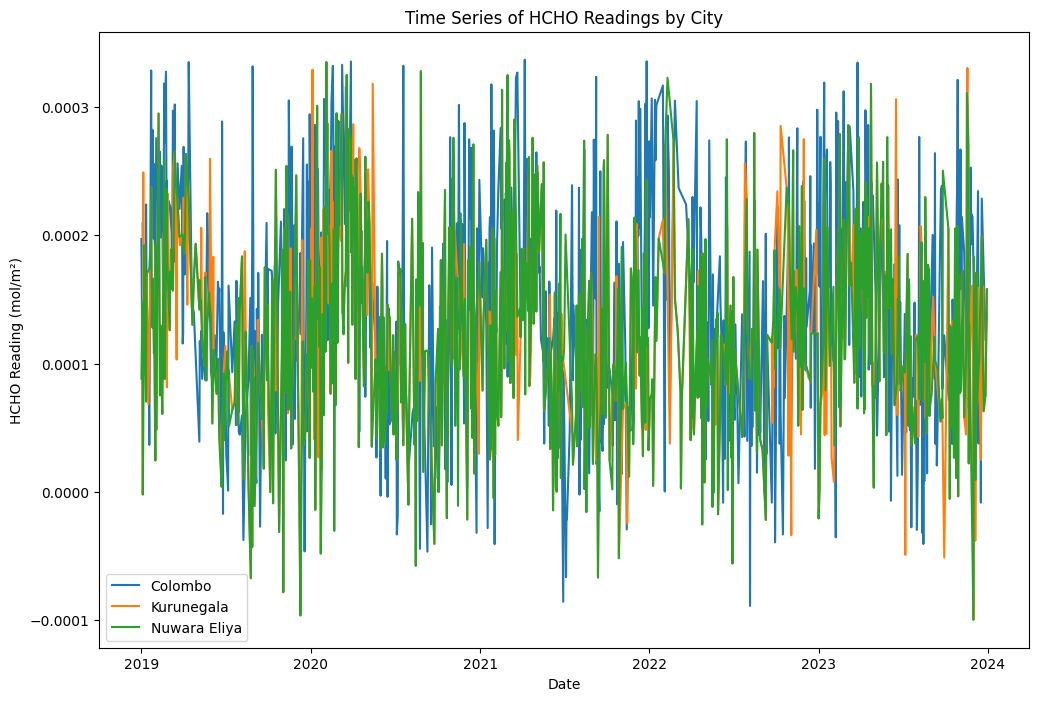

In [66]:
plt.figure(figsize=(12, 8))

# Plot time series graphs for each city
for city_data, city_name in zip([merged_colombo, merged_kurunegala, merged_nuwara_eliya], ["Colombo", "Kurunegala", "Nuwara Eliya"]):
    sns.lineplot(data=city_data, x="Current Date", y="HCHO reading", label=city_name)

plt.title('Time Series of HCHO Readings by City')
plt.xlabel('Date')
plt.ylabel('HCHO Reading (mol/m²)')
plt.legend()
plt.show()


In [67]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import numpy as np

# Define a function to fit ARIMA model and make predictions
def fit_arima_model(train, test, order):
    history = [x for x in train]
    predictions = list()
    for t in range(len(test)):
        model = ARIMA(history, order=order)
        model_fit = model.fit()
        yhat = model_fit.forecast()[0]
        predictions.append(yhat)
        history.append(test[t])
    # Calculate RMSE
    rmse = np.sqrt(mean_squared_error(test, predictions))
    return predictions, rmse

# Define the order for ARIMA model (p, d, q)
order = (5,1,0)  # Example order, you may need to tune this

# Iterate over each city and fit ARIMA model
cities_data = {
    "COLOMBO": merged_colombo,
    "KURUNEGALA": merged_kurunegala,
    "NUWARA": merged_nuwara_eliya
}

for city, data in cities_data.items():
    print(f"Model for {city}")
    city_data = data['HCHO reading'].values
    train_size = int(len(city_data) * 0.8)
    train, test = city_data[:train_size], city_data[train_size:]
    predictions, rmse = fit_arima_model(train, test, order)
    print(f"RMSE: {rmse}")
    print()


Model for COLOMBO


/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood op

LinAlgError: Schur decomposition solver error.